# Workshop-3 · Part A · Feature engineering and model training

**Course:** ETL (G01) · **Official guide:** Workshop-3, Part A, Step 3 (feature engineering) and Step 4 (train the regression model).

**Goal:** explore the relationships between the variables, select and justify the features, train a simple regression model inside a scikit-learn `Pipeline`, evaluate it with MAE, RMSE and R², and save the artifacts used by the streaming pipeline.

| | |
|---|---|
| Input | `data/processed/happiness_unified.csv` (created by `eda.ipynb`) |
| Outputs | `models/model.pkl` (preprocessing + model) and `data/streaming/happiness_stream.csv` (the 30% test split that the Kafka producer will send) |
| Deliverables of this notebook | training notebook, evaluation metrics (section 6), serialized model (section 7) |

**Contents:** 0 Setup · 1 Load · 2 Descriptive statistics and visualizations · 3 Feature selection · 4 Train/test split · 5 Reference comparison of the suggested models · 6 Final model and evaluation · 7 Save the artifacts and verify them · 8 Summary of decisions

## 0. Setup
Run it with the project's `.venv` kernel. Paths are resolved from the project root.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "happiness_unified.csv"
STREAMING_DIR = PROJECT_ROOT / "data" / "streaming"
MODELS_DIR = PROJECT_ROOT / "models"
STREAMING_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

IDENTIFIERS = ["country", "year"]
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption"]
TARGET = "score"
TEST_SIZE = 0.30
RANDOM_STATE = 42


def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}


print("Project root:", PROJECT_ROOT)
print("scikit-learn:", sklearn.__version__)

Project root: c:\Users\Daniel\Desktop\UAO\V Semestre\ETL\ETL_2026-2_Workshop-3
scikit-learn: 1.9.1


## 1. Load the unified dataset

In [2]:
data = pd.read_csv(PROCESSED_PATH)

assert list(data.columns) == IDENTIFIERS + FEATURES + [TARGET]
assert data.isna().sum().sum() == 0
assert not data.duplicated(["country", "year"]).any()
assert TARGET not in FEATURES

print(f"{data.shape[0]} rows x {data.shape[1]} columns")
display(data.head())

781 rows x 9 columns


,country,year,gdp,family,health,freedom,generosity,corruption,score
0,Switzerland,2015,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,7.587
1,Iceland,2015,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,7.561
2,Denmark,2015,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,7.527
3,Norway,2015,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,7.522
4,Canada,2015,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,7.427


## 2. Descriptive statistics and visualizations
Relationships among the variables (GDP, social support, life expectancy and the rest) as the guide requests for the feature engineering step.

In [3]:
display(data[FEATURES + [TARGET]].describe().round(3))

corr = data[FEATURES + [TARGET]].corr().round(3)
display(corr)

,gdp,family,health,freedom,generosity,corruption,score
count,781.000,781.000,781.000,781.000,781.000,781.000,781.000
mean,0.915,1.079,0.612,0.411,0.219,0.125,5.377
std,0.405,0.330,0.248,0.153,0.122,0.106,1.127
min,0.000,0.000,0.000,0.000,0.000,0.000,2.693
25%,0.605,0.870,0.440,0.310,0.130,0.054,4.509
50%,0.982,1.125,0.647,0.431,0.202,0.091,5.321
75%,1.234,1.328,0.808,0.531,0.279,0.156,6.182
max,1.871,1.644,1.141,0.724,0.838,0.552,7.769


,gdp,family,health,freedom,generosity,corruption,score
gdp,1.000,0.593,0.788,0.346,-0.014,0.306,0.790
family,0.593,1.000,0.573,0.420,-0.038,0.126,0.651
health,0.788,0.573,1.000,0.341,0.011,0.251,0.743
freedom,0.346,0.420,0.341,1.000,0.291,0.460,0.553
generosity,-0.014,-0.038,0.011,0.291,1.000,0.319,0.138
corruption,0.306,0.126,0.251,0.460,0.319,1.000,0.398
score,0.790,0.651,0.743,0.553,0.138,0.398,1.000


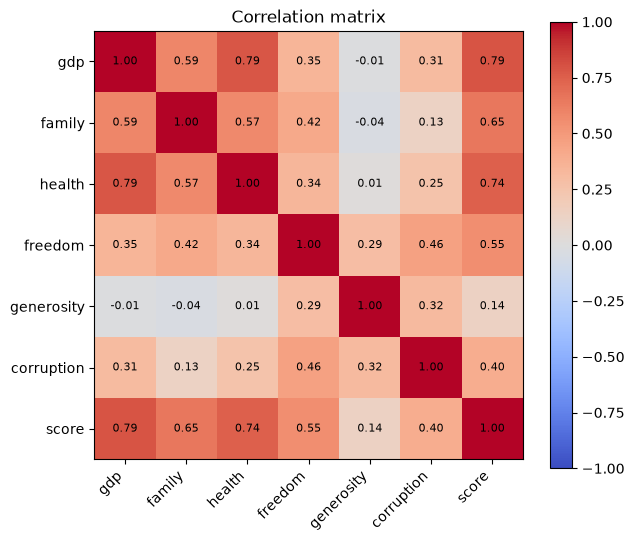

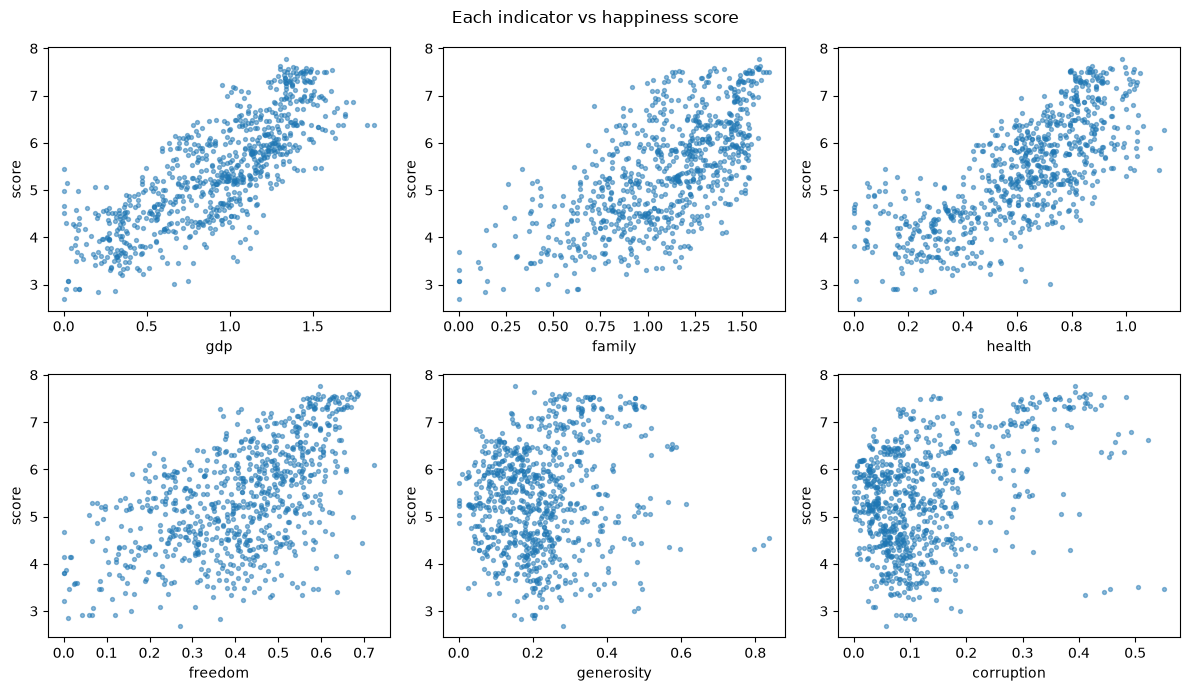

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
labels = list(corr.columns)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, c in zip(axes.ravel(), FEATURES):
    ax.scatter(data[c], data[TARGET], s=8, alpha=0.5)
    ax.set_xlabel(c)
    ax.set_ylabel(TARGET)
plt.suptitle("Each indicator vs happiness score")
plt.tight_layout()
plt.show()

**Observations**

- `gdp`, `health` and `family` show the strongest linear relationship with the score; `generosity` shows the weakest (see the correlation table).
- The indicators are also correlated with each other (for example `gdp` with `health` and `family`), which matters when interpreting the coefficients of a linear model.
- The indicators are the components of the score (the remaining part is the dystopia residual, which is excluded), so a good fit is expected and it is not a sign of leakage (see section 8 of `eda.ipynb`).

## 3. Feature selection

**Features:** the six numeric indicators. They are exactly the numeric fields of the event contract, so the streaming consumer will always be able to provide them.

**Target:** `score` (`actual_happiness_score` in the event). It is never part of the model input.

**Not features:** `country` and `year` identify the observation; they are kept only to trace and stream the events.

**Categorical data:** not needed. `country` has 164 distinct values, so one-hot encoding would create 164 columns and the model would tend to memorize countries (the same country appears in several years). A country that never appeared in training could also arrive in the stream. `year` is an identifier of the period, not a cause of the score.

**Scaling:** the indicators already share a similar range, and ordinary least squares does not need scaling to fit. A `StandardScaler` is still included in the `Pipeline` so the coefficients are comparable and, more importantly, so the consumer applies exactly the same preprocessing as in training by loading one single object.

**Target leakage:** ranks, standard error, confidence intervals, whiskers and dystopia residual were excluded in `eda.ipynb` because they are derived from the score.

In [5]:
feature_decisions = pd.DataFrame([
    {"column": "gdp", "role": "feature", "justification": "Strong relationship with the score; numeric field of the event contract."},
    {"column": "health", "role": "feature", "justification": "Strong relationship with the score; numeric field of the event contract."},
    {"column": "family", "role": "feature", "justification": "Strong relationship with the score; numeric field of the event contract."},
    {"column": "freedom", "role": "feature", "justification": "Moderate relationship with the score; numeric field of the event contract."},
    {"column": "corruption", "role": "feature", "justification": "Weaker relationship but informative; numeric field of the event contract."},
    {"column": "generosity", "role": "feature", "justification": "Weakest relationship; kept because it is part of the contract and costs nothing in a linear model."},
    {"column": "score", "role": "target", "justification": "Value to predict; sent as actual_happiness_score only for evaluation."},
    {"column": "country", "role": "identifier (not a feature)", "justification": "High cardinality and repeated across years: memorization risk and unseen values in the stream."},
    {"column": "year", "role": "identifier (not a feature)", "justification": "Identifies the observation period; it does not explain the score."},
]).set_index("column")
display(feature_decisions)

,role,justification
column,,
gdp,feature,Strong relationship with the score; numeric field of the event contract.
health,feature,Strong relationship with the score; numeric field of the event contract.
family,feature,Strong relationship with the score; numeric field of the event contract.
freedom,feature,Moderate relationship with the score; numeric field of the event contract.
corruption,feature,Weaker relationship but informative; numeric field of the event contract.
generosity,feature,Weakest relationship; kept because it is part of the contract and costs nothing in a linear model.
score,target,Value to predict; sent as actual_happiness_score only for evaluation.
country,identifier (not a feature),High cardinality and repeated across years: memorization risk and unseen values in the stream.
year,identifier (not a feature),Identifies the observation period; it does not explain the score.


## 4. Train/test split (70% / 30%)

The rows are split once with a fixed `random_state`, so the result is reproducible.

**Decision: the Kafka producer will send only the 30% test split.** If the producer sent every record, the model would predict rows it was trained on, and the dashboard KPI "average prediction error" would be falsely optimistic. The test split is saved in section 7 as `data/streaming/happiness_stream.csv`.

**Limitation (documented):** the split is random by row, so the same country can appear in train and test in different years. Since a country changes little from one year to the next, the test error can be slightly optimistic. This is accepted because the focus of the workshop is the pipeline integration, not model optimization.

In [6]:
train_df, test_df = train_test_split(data, test_size=TEST_SIZE, random_state=RANDOM_STATE)

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

train_keys = set(zip(train_df["country"], train_df["year"]))
test_keys = set(zip(test_df["country"], test_df["year"]))
assert not train_keys & test_keys, "an observation is in both splits"

print(f"Train: {len(train_df)} rows ({100 * len(train_df) / len(data):.1f}%)")
print(f"Test : {len(test_df)} rows ({100 * len(test_df) / len(data):.1f}%)")
display(pd.DataFrame({"train": train_df["year"].value_counts().sort_index(),
                      "test": test_df["year"].value_counts().sort_index()}))

Train: 546 rows (69.9%)
Test : 235 rows (30.1%)


,train,test
year,,
2015,107,51
2016,109,48
2017,107,48
2018,110,45
2019,113,43


## 5. Reference comparison of the three suggested models
The guide suggests Linear Regression, Random Forest and Decision Tree. All three are trained on the training split only, with the same preprocessing, and evaluated on both splits. **The comparison is a reference: the final model is chosen beforehand (section 6), not by looking at the test results.**

In [7]:
candidates = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
}

rows = []
for name, regressor in candidates.items():
    candidate = Pipeline([("scaler", StandardScaler()), ("regressor", regressor)]).fit(X_train, y_train)
    train_m = evaluate(y_train, candidate.predict(X_train))
    test_m = evaluate(y_test, candidate.predict(X_test))
    rows.append({"model": name,
                 "train_MAE": train_m["MAE"], "test_MAE": test_m["MAE"],
                 "train_RMSE": train_m["RMSE"], "test_RMSE": test_m["RMSE"],
                 "train_R2": train_m["R2"], "test_R2": test_m["R2"]})

comparison = pd.DataFrame(rows).set_index("model").round(3)
display(comparison)

,train_MAE,test_MAE,train_RMSE,test_RMSE,train_R2,test_R2
model,,,,,,
Linear Regression,0.423,0.432,0.545,0.557,0.768,0.752
Decision Tree,0.000,0.489,0.000,0.651,1.000,0.660
Random Forest,0.142,0.383,0.184,0.489,0.973,0.809


## 6. Final model and evaluation

**Model: Linear Regression inside a `Pipeline` (`StandardScaler` + `LinearRegression`).** It is the simplest of the suggested models, it is easy to explain and interpret, and it fits the problem: the score is built as a sum of the indicators. The guide states that the workshop is about the pipeline integration, not about squeezing the model.

In [8]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])
model.fit(X_train, y_train)

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

metrics = pd.DataFrame({"train": evaluate(y_train, pred_train), "test": evaluate(y_test, pred_test)}).round(4)
display(metrics)

regressor = model.named_steps["regressor"]
if hasattr(regressor, "coef_"):
    coefficients = pd.Series(regressor.coef_, index=FEATURES,
                             name="coefficient (standardized features)").sort_values(ascending=False)
    display(coefficients.round(3).to_frame())

,train,test
MAE,0.4225,0.4321
RMSE,0.5448,0.5566
R2,0.7675,0.7519


,coefficient (standardized features)
gdp,0.431
health,0.267
freedom,0.249
family,0.210
corruption,0.099
generosity,0.068


**Reading the results**

- Train and test metrics are close, so the model is stable: it does not memorize the training rows.
- The score is not reproduced perfectly because the dystopia residual (the remainder of the score) was excluded on purpose to avoid leakage. The error that remains is the part of the score that the six indicators cannot explain.
- The coefficients are expressed per standard deviation of each indicator, so they can be compared directly.

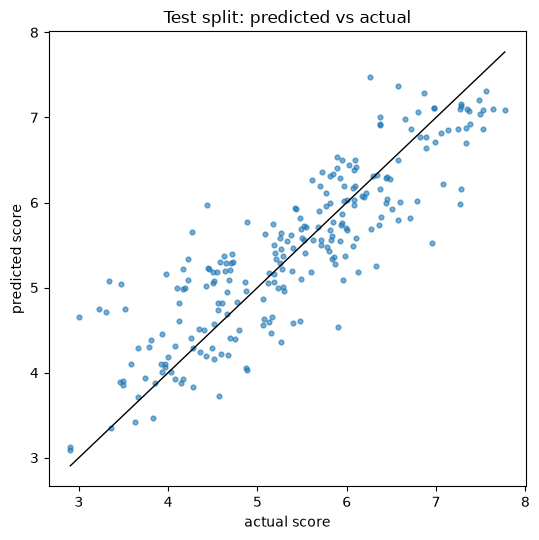

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, pred_test, s=12, alpha=0.6)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax.plot(lims, lims, color="black", linewidth=1)
ax.set_xlabel("actual score")
ax.set_ylabel("predicted score")
ax.set_title("Test split: predicted vs actual")
plt.tight_layout()
plt.show()

## 7. Save the artifacts and verify them

- `models/model.pkl`: the whole `Pipeline` (scaler + regressor). The consumer loads one object and calls `predict`, so training and streaming always apply the same preprocessing.
- `data/streaming/happiness_stream.csv`: the 30% test split, ordered by year and country, that the Kafka producer will send one record at a time.

`model.pkl` must be loaded with the same scikit-learn version used here (it is pinned in `requirements.txt`).

In [10]:
MODEL_PATH = MODELS_DIR / "model.pkl"
STREAM_PATH = STREAMING_DIR / "happiness_stream.csv"

joblib.dump(model, MODEL_PATH)

stream_df = test_df.sort_values(["year", "country"])[IDENTIFIERS + FEATURES + [TARGET]]
stream_df.to_csv(STREAM_PATH, index=False)

# verification: reload both files and check them
loaded = joblib.load(MODEL_PATH)
stream_check = pd.read_csv(STREAM_PATH)

assert list(loaded.feature_names_in_) == FEATURES
assert len(stream_check) == len(test_df)
assert not stream_check.isna().any().any()
assert not set(zip(stream_check["country"], stream_check["year"])) & train_keys
assert np.allclose(loaded.predict(stream_check[FEATURES]), model.predict(stream_check[FEATURES]))

print(f"Model saved   : {MODEL_PATH.relative_to(PROJECT_ROOT)} (scikit-learn {sklearn.__version__})")
print(f"Stream saved  : {STREAM_PATH.relative_to(PROJECT_ROOT)} ({len(stream_check)} rows)")
print("Features required by the model, in order:", list(loaded.feature_names_in_))

# smoke test: one record exactly as the consumer will do it
sample = stream_check.iloc[[0]]
predicted = float(loaded.predict(sample[FEATURES])[0])
actual = float(sample[TARGET].iloc[0])
print(f"Sample -> {sample['country'].iloc[0]} {sample['year'].iloc[0]}: actual {actual:.3f}, predicted {predicted:.3f}, error {actual - predicted:+.3f}")
print("All checks passed.")

Model saved   : models\model.pkl (scikit-learn 1.9.1)
Stream saved  : data\streaming\happiness_stream.csv (235 rows)
Features required by the model, in order: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
Sample -> Algeria 2015: actual 5.605, predicted 5.189, error +0.416
All checks passed.


## 8. Summary of decisions

| # | Decision | Justification |
|---|---|---|
| 1 | Features: `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption` | Numeric fields of the event contract; no leakage |
| 2 | `country` and `year` are identifiers, not features | High cardinality and memorization risk; unseen countries in the stream; `year` does not explain the score |
| 3 | Target: `score` (`actual_happiness_score` in the event) | Used only for training and evaluation, never as an input |
| 4 | `StandardScaler` + `LinearRegression` in one `Pipeline` | One object guarantees the same preprocessing in training and in the consumer |
| 5 | 70% / 30% random split, `random_state=42` | Suggested by the guide; reproducible |
| 6 | Linear Regression chosen beforehand, not by test results | Simplest suggested model and easy to explain; its train and test metrics are close (stable). The Random Forest scores somewhat better on the test split but overfits the training rows (section 5), and the workshop is about the pipeline, not about squeezing the model |
| 7 | Save with `joblib` as `models/model.pkl` | Standard for scikit-learn objects; version pinned in `requirements.txt` |
| 8 | The producer sends only the test split (`data/streaming/happiness_stream.csv`) | Evaluating on records the model was trained on would make the error KPI optimistic |
| 9 | Known limitation: a country can be in train and test in different years | Documented; accepted for this workshop |

**Next step:** `sql/create_tables.sql` and the PostgreSQL database, then `producer.py` and `consumer.py`. The consumer loads `model.pkl` and uses `feature_names_in_` to check that all the required features are present in each event.